<a href="https://colab.research.google.com/github/Manu26519/Presentacion-Program/blob/main/ppp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip -q install kagglehub

import kagglehub
import os
import glob
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, HTML

# Descargar la versión más reciente del dataset
path = kagglehub.dataset_download(
    "gauthamvijayaraj/spotify-tracks-dataset-updated-every-week"
)

print("Path to dataset files:", path)

# Buscar spotify_tracks.csv dentro de la carpeta descargada
archivos = glob.glob(
    os.path.join(path, "**", "spotify_tracks.csv"),
    recursive=True
)

if not archivos:
    raise FileNotFoundError(
        f"No encontré spotify_tracks.csv dentro de: {path}"
    )

ruta_csv = archivos[0]
df_original = pd.read_csv(ruta_csv, low_memory=False)

print("Archivo cargado:", ruta_csv)
print("Tamaño original:", df_original.shape)
display(df_original.head())

100%|██████████| 4.72M/4.72M [00:01<00:00, 4.13MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/gauthamvijayaraj/spotify-tracks-dataset-updated-every-week/versions/2
Archivo cargado: /root/.cache/kagglehub/datasets/gauthamvijayaraj/spotify-tracks-dataset-updated-every-week/versions/2/spotify_tracks.csv
Tamaño original: (62317, 22)


,track_id,track_name,artist_name,year,popularity,artwork_url,album_name,acousticness,danceability,duration_ms,...,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,track_url,language
0,2r0ROhr7pRN4MXDMT1fEmd,"Leo Das Entry (From ""Leo"")",Anirudh Ravichander,2024,59,https://i.scdn.co/image/ab67616d0000b273ce9c65...,"Leo Das Entry (From ""Leo"")",0.0241,0.753,97297.0,...,8.0,0.1000,-5.994,0.0,0.1030,110.997,4.0,0.459,https://open.spotify.com/track/2r0ROhr7pRN4MXD...,Tamil
1,4I38e6Dg52a2o2a8i5Q5PW,AAO KILLELLE,"Anirudh Ravichander, Pravin Mani, Vaishali Sri...",2024,47,https://i.scdn.co/image/ab67616d0000b273be1b03...,AAO KILLELLE,0.0851,0.780,207369.0,...,10.0,0.0951,-5.674,0.0,0.0952,164.995,3.0,0.821,https://open.spotify.com/track/4I38e6Dg52a2o2a...,Tamil
2,59NoiRhnom3lTeRFaBzOev,Mayakiriye Sirikiriye - Orchestral EDM,"Anirudh Ravichander, Anivee, Alvin Bruno",2024,35,https://i.scdn.co/image/ab67616d0000b27334a1dd...,Mayakiriye Sirikiriye (Orchestral EDM),0.0311,0.457,82551.0,...,2.0,0.0831,-8.937,0.0,0.1530,169.996,4.0,0.598,https://open.spotify.com/track/59NoiRhnom3lTeR...,Tamil
3,5uUqRQd385pvLxC8JX3tXn,Scene Ah Scene Ah - Experimental EDM Mix,"Anirudh Ravichander, Bharath Sankar, Kabilan, ...",2024,24,https://i.scdn.co/image/ab67616d0000b27332e623...,Scene Ah Scene Ah (Experimental EDM Mix),0.2270,0.718,115831.0,...,7.0,0.1240,-11.104,1.0,0.4450,169.996,4.0,0.362,https://open.spotify.com/track/5uUqRQd385pvLxC...,Tamil
4,1KaBRg2xgNeCljmyxBH1mo,Gundellonaa X I Am A Disco Dancer - Mashup,"Anirudh Ravichander, Benny Dayal, Leon James, ...",2024,22,https://i.scdn.co/image/ab67616d0000b2735a59b6...,Gundellonaa X I Am a Disco Dancer (Mashup),0.0153,0.689,129621.0,...,7.0,0.3450,-9.637,1.0,0.1580,128.961,4.0,0.593,https://open.spotify.com/track/1KaBRg2xgNeCljm...,Tamil


In [5]:
# Limpiar los nombres de las columnas e identificar variables
df = df_original.copy()

# Estandarizar los nombres de columnas
df.columns = [
    re.sub(
        r"[^a-z0-9]+",
        "_",
        str(col).strip().lower()
    ).strip("_")
    for col in df.columns
]

# Quitar columnas de índice que a veces aparecen en archivos CSV
df = df.drop(
    columns=[
        col for col in df.columns
        if col.startswith("unnamed")
    ],
    errors="ignore"
)

print("Columnas disponibles:")
print(df.columns.tolist())

# Encontrar la columna que contiene el año o fecha de lanzamiento
posibles_anios = [
    "year",
    "release_year",
    "release_date",
    "album_release_date"
]

columna_anio = next(
    (col for col in posibles_anios if col in df.columns),
    None
)

if columna_anio is None:
    raise ValueError(
        "No se encontró una columna de año o fecha. "
        f"Columnas disponibles: {df.columns.tolist()}"
    )

# Encontrar nombres posibles para canción y artista
posibles_canciones = [
    "track_name",
    "name",
    "song_name",
    "track"
]

posibles_artistas = [
    "artist_name",
    "artists",
    "artist"
]

columna_cancion = next(
    (col for col in posibles_canciones if col in df.columns),
    None
)

columna_artista = next(
    (col for col in posibles_artistas if col in df.columns),
    None
)

if columna_cancion is None:
    raise ValueError("No se encontró una columna con el nombre de la canción.")

if columna_artista is None:
    raise ValueError("No se encontró una columna con el nombre del artista.")

if "popularity" not in df.columns:
    raise ValueError("No se encontró la columna popularity.")

print("Columna de año:", columna_anio)
print("Columna de canción:", columna_cancion)
print("Columna de artista:", columna_artista)


Columnas disponibles:
['track_id', 'track_name', 'artist_name', 'year', 'popularity', 'artwork_url', 'album_name', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence', 'track_url', 'language']
Columna de año: year
Columna de canción: track_name
Columna de artista: artist_name


In [6]:
#impiar datos y filtrar los años 2000–2024
filas_originales = len(df)

# Extraer el año, también si la columna contiene fechas como 2024-05-01
df["year"] = pd.to_numeric(
    df[columna_anio]
    .astype("string")
    .str.extract(r"((?:19|20)\d{2})")[0],
    errors="coerce"
)

# Convertir variables a números
columnas_numericas = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

for col in columnas_numericas:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Eliminar filas idénticas
df = df.drop_duplicates()

# Eliminar canciones duplicadas por track_id si existe
if "track_id" in df.columns:
    df["_completitud"] = df.notna().sum(axis=1)

    df = (
        df.sort_values("_completitud", ascending=False)
          .drop_duplicates(subset=["track_id"], keep="first")
          .drop(columns="_completitud")
    )
else:
    # Si no hay track_id, usar nombre de canción, artista y año
    df = df.drop_duplicates(
        subset=[columna_cancion, columna_artista, "year"]
    )

# Mantener solamente los años solicitados
df = df[df["year"].between(2000, 2024)].copy()
df["year"] = df["year"].astype(int)

# Validar popularidad: la escala usual es de 0 a 100
df.loc[
    ~df["popularity"].between(0, 100),
    "popularity"
] = np.nan

# Validar características de audio que deben estar entre 0 y 1
caracteristicas_0_1 = [
    "danceability",
    "energy",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence"
]

for col in caracteristicas_0_1:
    if col in df.columns:
        valores_invalidos = (
            df[col].notna()
            & ~df[col].between(0, 1)
        )
        df.loc[valores_invalidos, col] = np.nan

# Convertir duración de milisegundos a minutos
if "duration_ms" in df.columns:
    df.loc[df["duration_ms"] <= 0, "duration_ms"] = np.nan
    df["duration_min"] = df["duration_ms"] / 60000

# Eliminar filas sin datos esenciales para el análisis
df = df.dropna(
    subset=["year", "popularity", columna_cancion, columna_artista]
).copy()

print("Filas originales:", filas_originales)
print("Filas después de limpiar:", len(df))
print("Primer año del análisis:", df["year"].min())
print("Último año del análisis:", df["year"].max())
print("Años presentes:", sorted(df["year"].unique()))

Filas originales: 62317
Filas después de limpiar: 56404
Primer año del análisis: 2000
Último año del análisis: 2024
Años presentes: [np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


In [7]:
#Resumen por año
todos_los_anios = pd.Index(range(2000, 2025), name="year")

conteo_anual = (
    df.groupby("year")
      .size()
      .reindex(todos_los_anios, fill_value=0)
      .rename("numero_canciones")
)

metricas = [
    col for col in [
        "popularity",
        "danceability",
        "energy",
        "valence",
        "acousticness",
        "instrumentalness",
        "speechiness",
        "liveness",
        "loudness",
        "tempo",
        "duration_min"
    ]
    if col in df.columns
]

promedios_anuales = (
    df.groupby("year")[metricas]
      .mean()
      .reindex(todos_los_anios)
)

medianas_anuales = (
    df.groupby("year")[metricas]
      .median()
      .reindex(todos_los_anios)
)

tabla_anual = pd.concat(
    [
        conteo_anual,
        promedios_anuales.add_suffix("_promedio"),
        medianas_anuales.add_suffix("_mediana")
    ],
    axis=1
)

print("Resumen de todos los años, 2000–2024:")
display(tabla_anual.round(2))

Resumen de todos los años, 2000–2024:


,numero_canciones,popularity_promedio,danceability_promedio,energy_promedio,valence_promedio,acousticness_promedio,instrumentalness_promedio,speechiness_promedio,liveness_promedio,loudness_promedio,...,danceability_mediana,energy_mediana,valence_mediana,acousticness_mediana,instrumentalness_mediana,speechiness_mediana,liveness_mediana,loudness_mediana,tempo_mediana,duration_min_mediana
year,,,,,,,,,,,,,,,,,,,,,
2000,376,21.22,0.58,0.61,0.51,0.25,0.18,0.09,0.27,-10.70,...,0.62,0.65,0.52,0.11,0.0,0.05,0.14,-9.08,112.22,4.56
2001,493,19.74,0.59,0.57,0.53,0.37,0.15,0.08,0.19,-10.92,...,0.64,0.60,0.57,0.24,0.0,0.05,0.12,-9.49,115.00,4.77
2002,494,14.99,0.59,0.60,0.51,0.30,0.13,0.09,0.19,-10.62,...,0.64,0.63,0.54,0.18,0.0,0.05,0.12,-9.33,108.56,4.33
2003,594,14.97,0.59,0.62,0.52,0.29,0.18,0.09,0.18,-9.84,...,0.64,0.64,0.55,0.19,0.0,0.06,0.12,-8.87,117.45,4.69
2004,527,16.07,0.59,0.61,0.51,0.33,0.17,0.08,0.20,-389.37,...,0.64,0.65,0.57,0.27,0.0,0.05,0.13,-9.23,115.03,4.69
2005,854,12.55,0.61,0.62,0.57,0.34,0.15,0.08,0.17,-9.19,...,0.64,0.69,0.61,0.23,0.0,0.05,0.11,-7.93,115.94,4.47
2006,786,12.98,0.56,0.58,0.49,0.40,0.21,0.08,0.21,-10.19,...,0.61,0.65,0.52,0.31,0.0,0.05,0.12,-8.22,114.11,4.47
2007,865,13.74,0.56,0.60,0.49,0.37,0.15,0.08,0.22,-9.16,...,0.59,0.64,0.50,0.27,0.0,0.05,0.13,-7.79,117.67,4.30
2008,977,15.58,0.57,0.60,0.46,0.35,0.24,0.08,0.20,-214.27,...,0.63,0.65,0.50,0.26,0.0,0.05,0.12,-7.89,117.98,4.26


In [ ]:
#Comparar 2004, 2014 y 2024
anios_comparacion = [2004, 2014, 2024]

tabla_comparacion = tabla_anual.loc[anios_comparacion]

print("Comparación de 2004, 2014 y 2024:")
display(tabla_comparacion.round(2))

# Diferencias entre los promedios de los años comparados
pares = [
    (2004, 2014),
    (2014, 2024),
    (2004, 2024)
]

filas_diferencias = []

for anio_inicial, anio_final in pares:
    fila = {
        "comparacion": f"{anio_inicial}–{anio_final}",
        "canciones_año_inicial": int(conteo_anual.loc[anio_inicial]),
        "canciones_año_final": int(conteo_anual.loc[anio_final])
    }

    for metrica in metricas:
        valor_inicial = promedios_anuales.loc[anio_inicial, metrica]
        valor_final = promedios_anuales.loc[anio_final, metrica]

        fila[f"{metrica}_diferencia"] = (
            valor_final - valor_inicial
            if pd.notna(valor_inicial) and pd.notna(valor_final)
            else np.nan
        )

    filas_diferencias.append(fila)

tabla_diferencias = pd.DataFrame(filas_diferencias)

print("Diferencias entre años:")
display(tabla_diferencias.round(2))

In [8]:
#Tajerta de resumen
# Métricas generales
total_canciones = len(df)
popularidad_general = df["popularity"].mean()

# Mejor año según popularidad promedio
anios_con_datos = promedios_anuales["popularity"].dropna()

if len(anios_con_datos) > 0:
    mejor_anio = int(anios_con_datos.idxmax())
    popularidad_mejor_anio = anios_con_datos.max()
else:
    mejor_anio = "Sin datos"
    popularidad_mejor_anio = np.nan

# Artista con mayor popularidad promedio en todo el periodo
resumen_artistas_total = (
    df.groupby(columna_artista)
      .agg(
          popularidad_promedio=("popularity", "mean"),
          numero_canciones=("popularity", "size")
      )
      .sort_values(
          ["popularidad_promedio", "numero_canciones"],
          ascending=False
      )
)

if len(resumen_artistas_total) > 0:
    mejor_artista = resumen_artistas_total.index[0]
    popularidad_mejor_artista = resumen_artistas_total.iloc[0][
        "popularidad_promedio"
    ]
else:
    mejor_artista = "Sin datos"
    popularidad_mejor_artista = np.nan

def tarjeta(titulo, valor, detalle=""):
    return f"""
    <div style="
        background:#f3f6fa;
        border-top:5px solid #1683e8;
        border-radius:12px;
        padding:18px;
        min-width:190px;
        flex:1;
        font-family:Arial,sans-serif;
        box-shadow:0 2px 6px rgba(0,0,0,0.08);
    ">
      <div style="font-size:14px;color:#555;">{titulo}</div>
      <div style="font-size:27px;font-weight:bold;color:#111;margin-top:6px;">
        {valor}
      </div>
      <div style="font-size:13px;color:#666;margin-top:5px;">
        {detalle}
      </div>
    </div>
    """

tarjetas_resumen = [
    tarjeta(
        "Canciones analizadas",
        f"{total_canciones:,}",
        "Años 2000–2024"
    ),
    tarjeta(
        "Popularidad promedio",
        f"{popularidad_general:.1f}/100",
        "En todo el periodo"
    ),
    tarjeta(
        "Año con mayor popularidad promedio",
        str(mejor_anio),
        (
            f"Promedio {popularidad_mejor_anio:.1f}/100"
            if pd.notna(popularidad_mejor_anio)
            else "Sin datos disponibles"
        )
    ),
    tarjeta(
        "Artista con mayor promedio",
        html.escape(str(mejor_artista)),
        (
            f"{popularidad_mejor_artista:.1f}/100 en promedio"
            if pd.notna(popularidad_mejor_artista)
            else "Sin datos disponibles"
        )
    )
]

display(HTML(
    "<div style='display:flex;gap:14px;flex-wrap:wrap;'>"
    + "".join(tarjetas_resumen)
    + "</div>"
))

In [9]:
#Top artista por año

MIN_CANCIONES_ARTISTA = 2
TOP_N = 5

resumen_artistas_anio = (
    df.groupby(["year", columna_artista], as_index=False)
      .agg(
          popularidad_promedio=("popularity", "mean"),
          numero_canciones=("popularity", "size")
      )
)

# Para cada año, preferir artistas con al menos dos canciones.
# Si ese año no tiene ninguno, se usan todos los artistas disponibles.
listas_por_anio = []

for anio in range(2000, 2025):
    datos_anio = resumen_artistas_anio[
        resumen_artistas_anio["year"] == anio
    ].copy()

    if datos_anio.empty:
        continue

    elegibles = datos_anio[
        datos_anio["numero_canciones"] >= MIN_CANCIONES_ARTISTA
    ]

    if elegibles.empty:
        elegibles = datos_anio

    top_anio = (
        elegibles
        .sort_values(
            ["popularidad_promedio", "numero_canciones"],
            ascending=[False, False]
        )
        .head(TOP_N)
    )

    listas_por_anio.append(top_anio)

top_artistas_por_anio = pd.concat(
    listas_por_anio,
    ignore_index=True
) if listas_por_anio else pd.DataFrame()

if top_artistas_por_anio.empty:
    print("No se encontraron artistas para generar el ranking.")
else:
    top_artistas_por_anio = top_artistas_por_anio.rename(
        columns={
            "year": "Año",
            columna_artista: "Artista",
            "popularidad_promedio": "Popularidad promedio",
            "numero_canciones": "Número de canciones"
        }
    )

    top_artistas_por_anio["Popularidad promedio"] = (
        top_artistas_por_anio["Popularidad promedio"].round(2)
    )

    print(f"Top {TOP_N} artistas por año:")
    display(top_artistas_por_anio)

Top 5 artistas por año:


,Año,Artista,Popularidad promedio,Número de canciones
0,2000,"Hans Zimmer, Klaus Badelt, Lisa Gerrard, Gavin...",57.00,2
1,2000,Linkin Park,54.12,40
2,2000,*NSYNC,46.00,16
3,2000,Backstreet Boys,45.79,14
4,2000,Shakira,38.55,11
...,...,...,...,...
120,2024,"Karan Aujla, Mxrci",72.50,2
121,2024,"Hanumankind, Kalmi",72.00,2
122,2024,"Shilpa Rao, Anirudh Ravichander, Ramajogayya S...",67.50,2
123,2024,"Thaman S, Sri Krishna, Sahithi Chaganti, Mahes...",67.50,2


In [10]:
#Tarjetas para los artistas número uno de cada año
if not top_artistas_por_anio.empty:
    primeros_artistas = (
        top_artistas_por_anio
        .sort_values(
            ["Año", "Popularidad promedio", "Número de canciones"],
            ascending=[True, False, False]
        )
        .groupby("Año", as_index=False)
        .first()
    )

    tarjetas_artistas = []

    for _, fila in primeros_artistas.iterrows():
        artista = html.escape(str(fila["Artista"]))

        tarjetas_artistas.append(
            f"""
            <div style="
                background:#f3f6fa;
                border-top:4px solid #1683e8;
                border-radius:10px;
                padding:14px;
                min-width:180px;
                flex:1;
                font-family:Arial,sans-serif;
                margin:4px;
            ">
              <div style="font-size:13px;color:#555;">
                Artista destacado · {int(fila["Año"])}
              </div>
              <div style="
                  font-size:18px;
                  font-weight:bold;
                  margin:6px 0;
                  color:#111;
              ">
                {artista}
              </div>
              <div style="font-size:13px;color:#555;">
                Popularidad promedio:
                <b>{fila["Popularidad promedio"]:.1f}/100</b>
              </div>
              <div style="font-size:13px;color:#555;">
                Canciones: {int(fila["Número de canciones"])}
              </div>
            </div>
            """
        )

    display(HTML(
        "<div style='display:flex;gap:10px;flex-wrap:wrap;'>"
        + "".join(tarjetas_artistas)
        + "</div>"
    ))

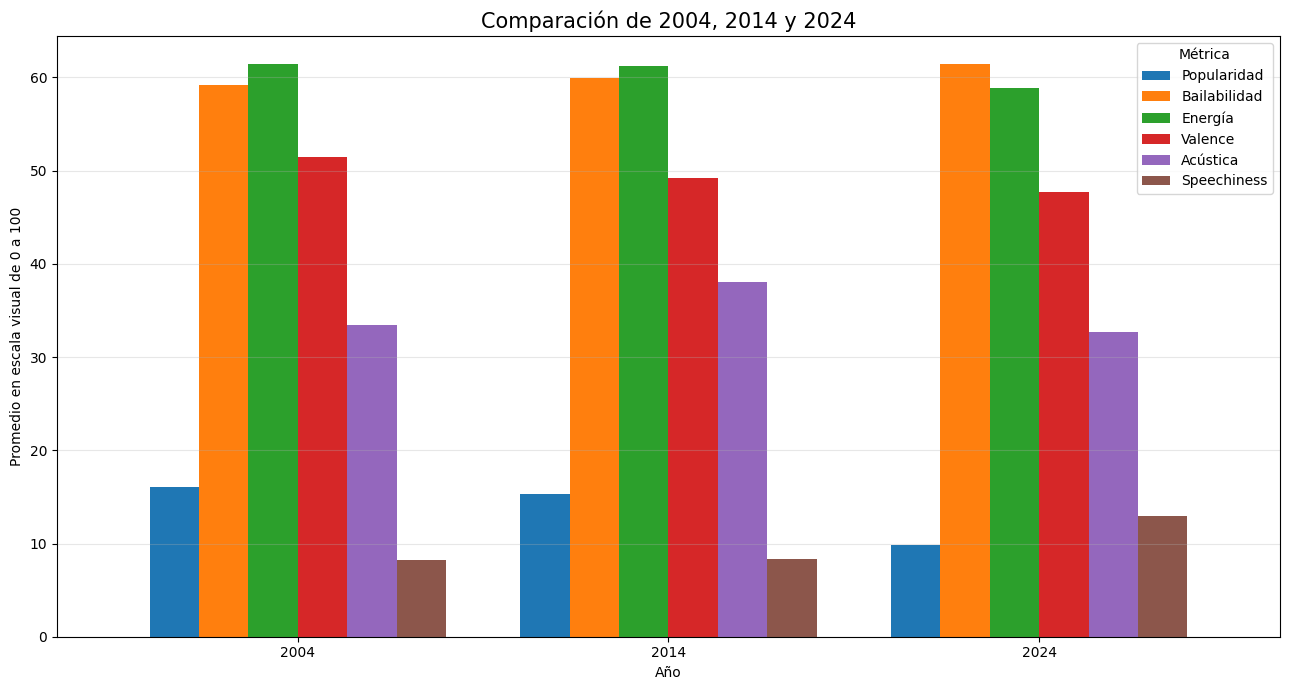

In [13]:
#Gráfico 1: comparar características en 2004, 2014 y 2024
anios_comparacion = [2004, 2014, 2024]

metricas_comparar = [
    col for col in [
        "popularity",
        "danceability",
        "energy",
        "valence",
        "acousticness",
        "speechiness"
    ]
    if col in promedios_anuales.columns
]

comparacion_grafico = promedios_anuales.loc[
    anios_comparacion,
    metricas_comparar
].copy()

for col in comparacion_grafico.columns:
    if col != "popularity":
        comparacion_grafico[col] = comparacion_grafico[col] * 100

comparacion_grafico = comparacion_grafico.rename(
    columns={
        "popularity": "Popularidad",
        "danceability": "Bailabilidad",
        "energy": "Energía",
        "valence": "Valence",
        "acousticness": "Acústica",
        "speechiness": "Speechiness"
    }
)

comparacion_grafico.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.title("Comparación de 2004, 2014 y 2024", fontsize=15)
plt.xlabel("Año")
plt.ylabel("Promedio en escala visual de 0 a 100")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

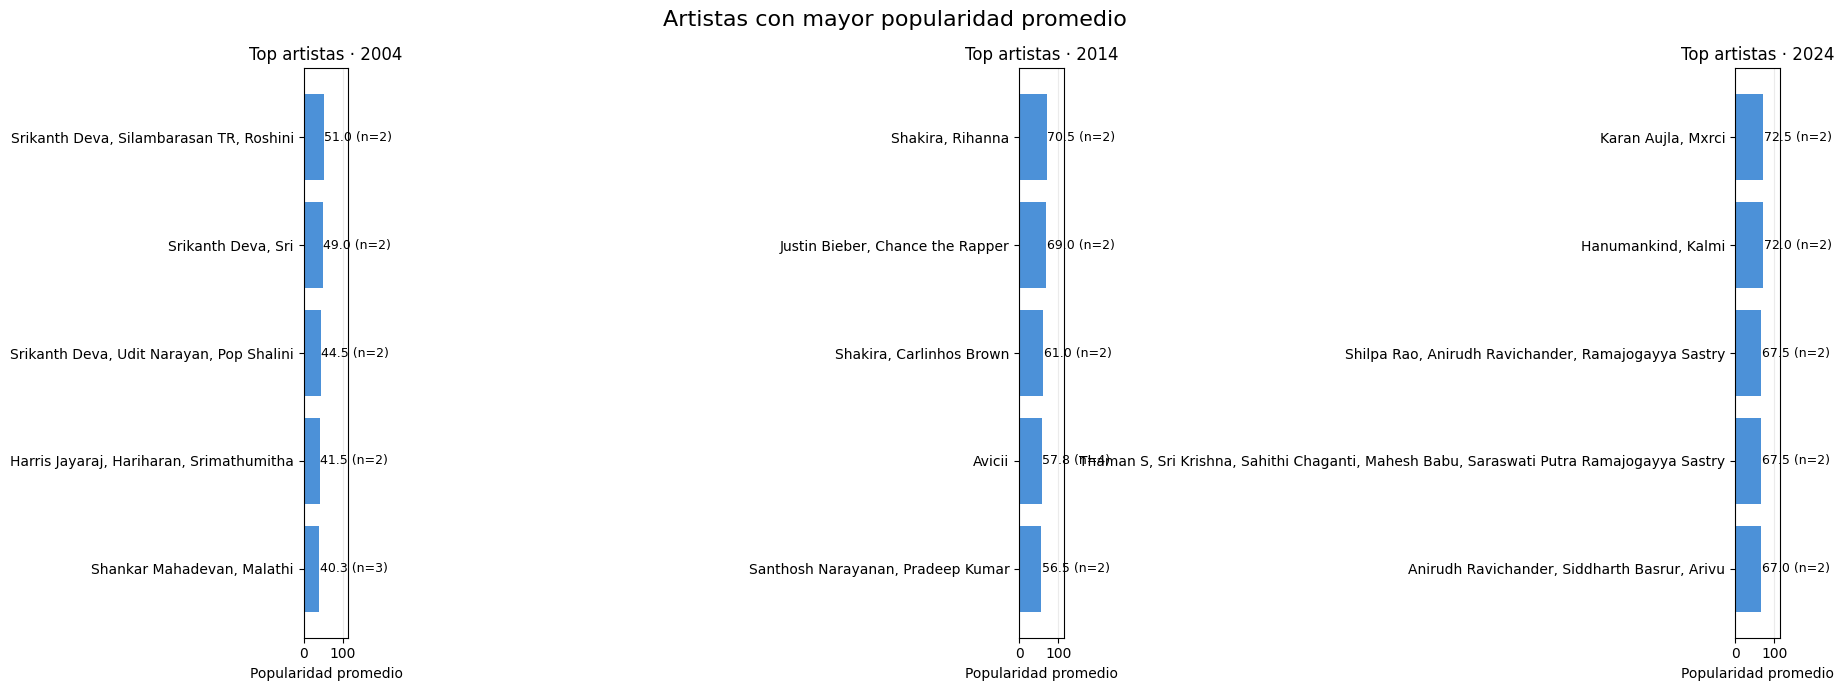

In [14]:
if top_artistas_por_anio.empty:
    print("No hay datos para el gráfico de artistas.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharex=True)

    for ax, anio in zip(axes, anios_comparacion):
        datos = top_artistas_por_anio[
            top_artistas_por_anio["Año"] == anio
        ].copy()

        if datos.empty:
            ax.set_title(f"{anio}: sin datos")
            ax.axis("off")
            continue

        datos = datos.sort_values("Popularidad promedio")

        barras = ax.barh(
            datos["Artista"].astype(str),
            datos["Popularidad promedio"],
            color="#4c91d8"
        )

        ax.set_title(f"Top artistas · {anio}")
        ax.set_xlabel("Popularidad promedio")
        ax.set_xlim(0, 115)
        ax.grid(axis="x", alpha=0.25)

        # Etiquetar cada barra con popularidad y cantidad de canciones
        for barra, (_, fila) in zip(barras, datos.iterrows()):
            ax.text(
                barra.get_width() + 1,
                barra.get_y() + barra.get_height() / 2,
                (
                    f'{fila["Popularidad promedio"]:.1f} '
                    f'(n={int(fila["Número de canciones"])})'
                ),
                va="center",
                fontsize=9
            )

    fig.suptitle(
        "Artistas con mayor popularidad promedio",
        fontsize=16
    )
    plt.tight_layout()
    plt.show()

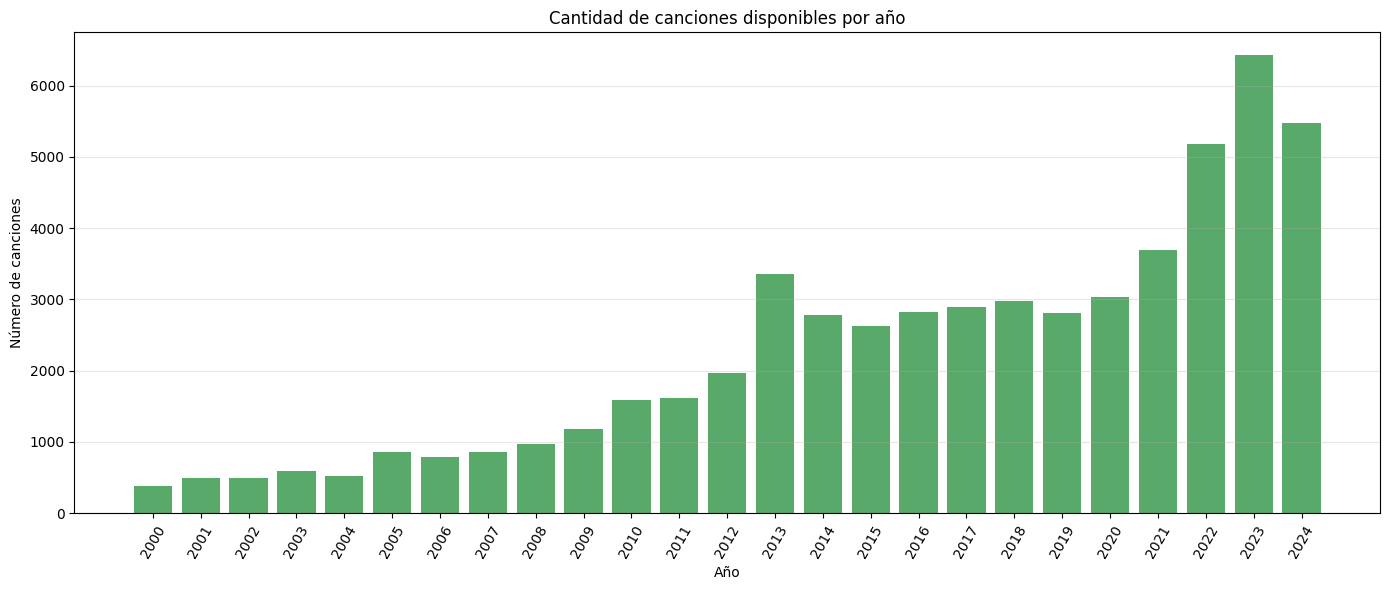

In [15]:
plt.figure(figsize=(14, 6))

plt.bar(
    conteo_anual.index,
    conteo_anual.values,
    color="#59a96a"
)

plt.title("Cantidad de canciones disponibles por año")
plt.xlabel("Año")
plt.ylabel("Número de canciones")
plt.xticks(range(2000, 2025, 1), rotation=60)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

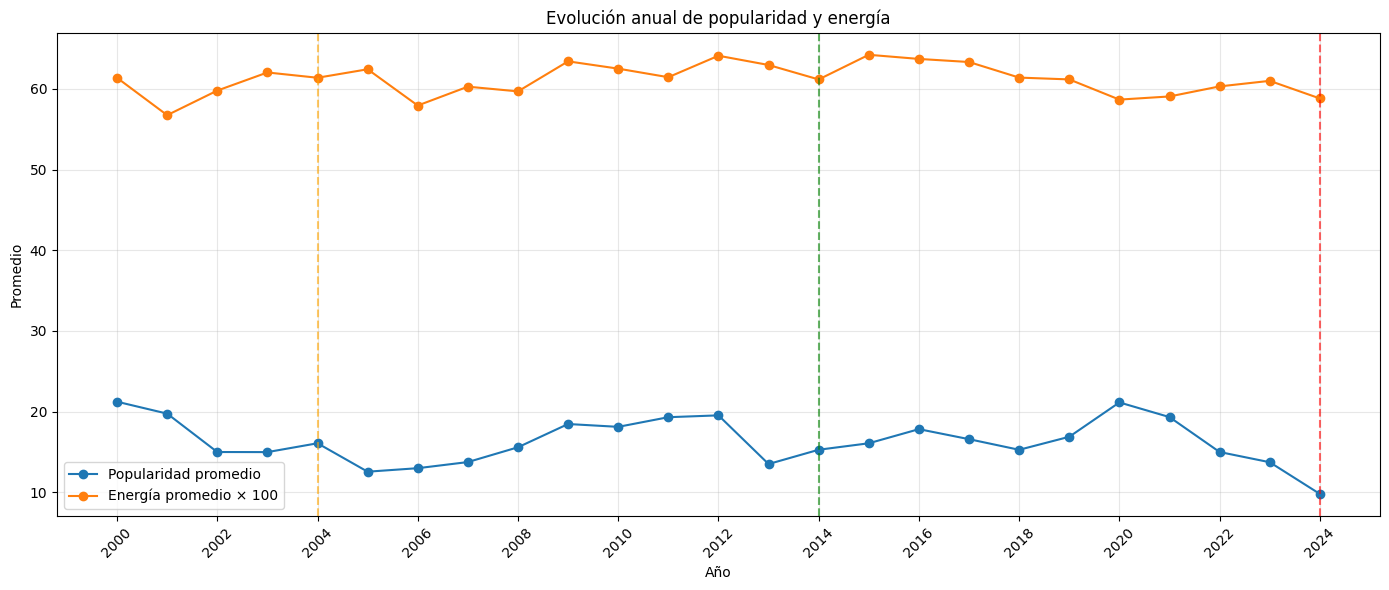

In [16]:
if "energy" in promedios_anuales.columns:
    plt.figure(figsize=(14, 6))

    plt.plot(
        promedios_anuales.index,
        promedios_anuales["popularity"],
        marker="o",
        label="Popularidad promedio"
    )

    plt.plot(
        promedios_anuales.index,
        promedios_anuales["energy"] * 100,
        marker="o",
        label="Energía promedio × 100"
    )

    for anio, color in [
        (2004, "orange"),
        (2014, "green"),
        (2024, "red")
    ]:
        plt.axvline(
            anio,
            linestyle="--",
            color=color,
            alpha=0.6
        )

    plt.title("Evolución anual de popularidad y energía")
    plt.xlabel("Año")
    plt.ylabel("Promedio")
    plt.xticks(range(2000, 2025, 2), rotation=45)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No está disponible la columna energy.")